In [3]:
import sys; sys.path.insert(0, "../src")
from data import load_all
import matplotlib.pyplot as plt

In [4]:
df = load_all()
local = df.tz_convert("Europe/London")

<Axes: xlabel='hour'>

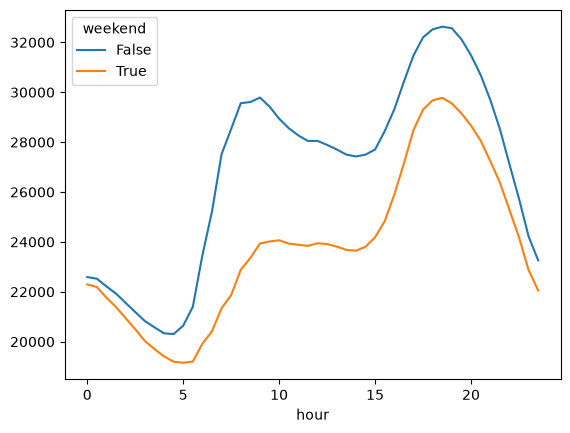

In [5]:
# 1. Weekday vs weekend profile
local["hour"] = local.index.hour + local.index.minute / 60
local["weekend"] = local.index.dayofweek >= 5
local.groupby(["hour", "weekend"])["demand"].mean().unstack().plot()

<Axes: xlabel='time'>

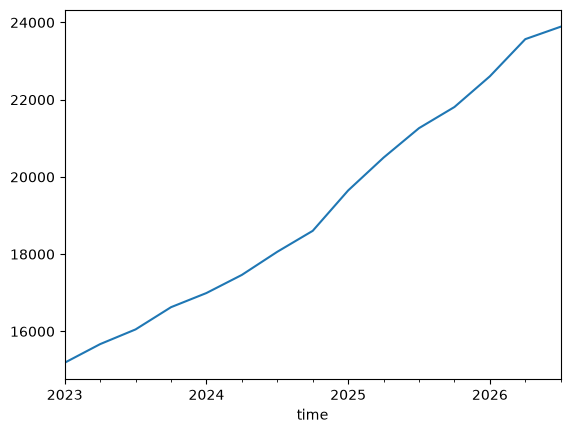

In [13]:
# 2. How fast did embedded solar capacity grow?
local["solar_capacity"].resample("QE").mean().plot()

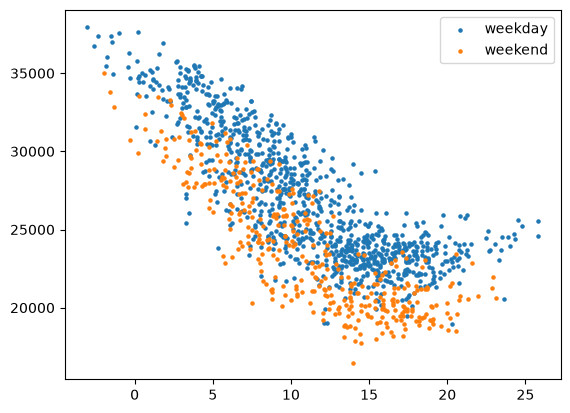

In [14]:
# 3. See the confounder: daily demand vs temperature, weekdays vs weekends
daily = local.resample("D").mean(numeric_only=True)
daily["weekend"] = daily.index.dayofweek >= 5
for w, g in daily.groupby("weekend"):
    plt.scatter(g.temperature, g.demand, s=5, label="weekend" if w else "weekday")
plt.legend()